# Figure S15: Fine-mapping annotation enrichment

Draw the saved logistic-model estimates from the Figure 1 enrichment plot as odds ratios on a log10 axis. Preserve the saved estimates, intervals, and adjusted P values.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The notebook reads the recorded figure data.
It does not rerun upstream QTL mapping unless a section explicitly says so.
New PDFs and PNGs go to `notebook_outputs/`. Inputs stay in place.
The source scripts are in `notebooks/current/`. Figures shown below are aggregate
plots. Do not print participant tables into a saved notebook.


## Scope

Odds ratios compare PIP 1 with PIP 0 within assay. Bars are saved 95% Wald intervals.

The notebook redraws saved model results. It does not rerun variant annotation, fine-mapping, or logistic regression.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the November 2 figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display the archived November 2 submission image for Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the saved enrichment estimates

Rebuild S15 from the logistic-regression summaries stored in the saved Figure 1 enrichment plot. No regression is fitted here. Odds ratios compare PIP = 1 with PIP = 0 within each assay.


In [2]:
saved <- readRDS(source_file("Fig1/objects/H.rds"))
enrichment <- saved$data %>%
  mutate(odds_ratio = exp(estimate), lower = exp(conf.low), upper = exp(conf.high),
         type = factor(type, c("eQTL", "sQTL", "pQTL")), significant = padj < 0.05)
stopifnot(all(is.finite(enrichment$odds_ratio)), all(enrichment$lower > 0),
          all(enrichment$upper >= enrichment$lower), !any(enrichment$separated))


## Draw the saved odds ratios

Points show saved odds ratios. Bars show saved 95% Wald intervals. The log10 axis displays odds ratios rather than log-odds coefficients. The alpha key uses the saved adjusted P values.


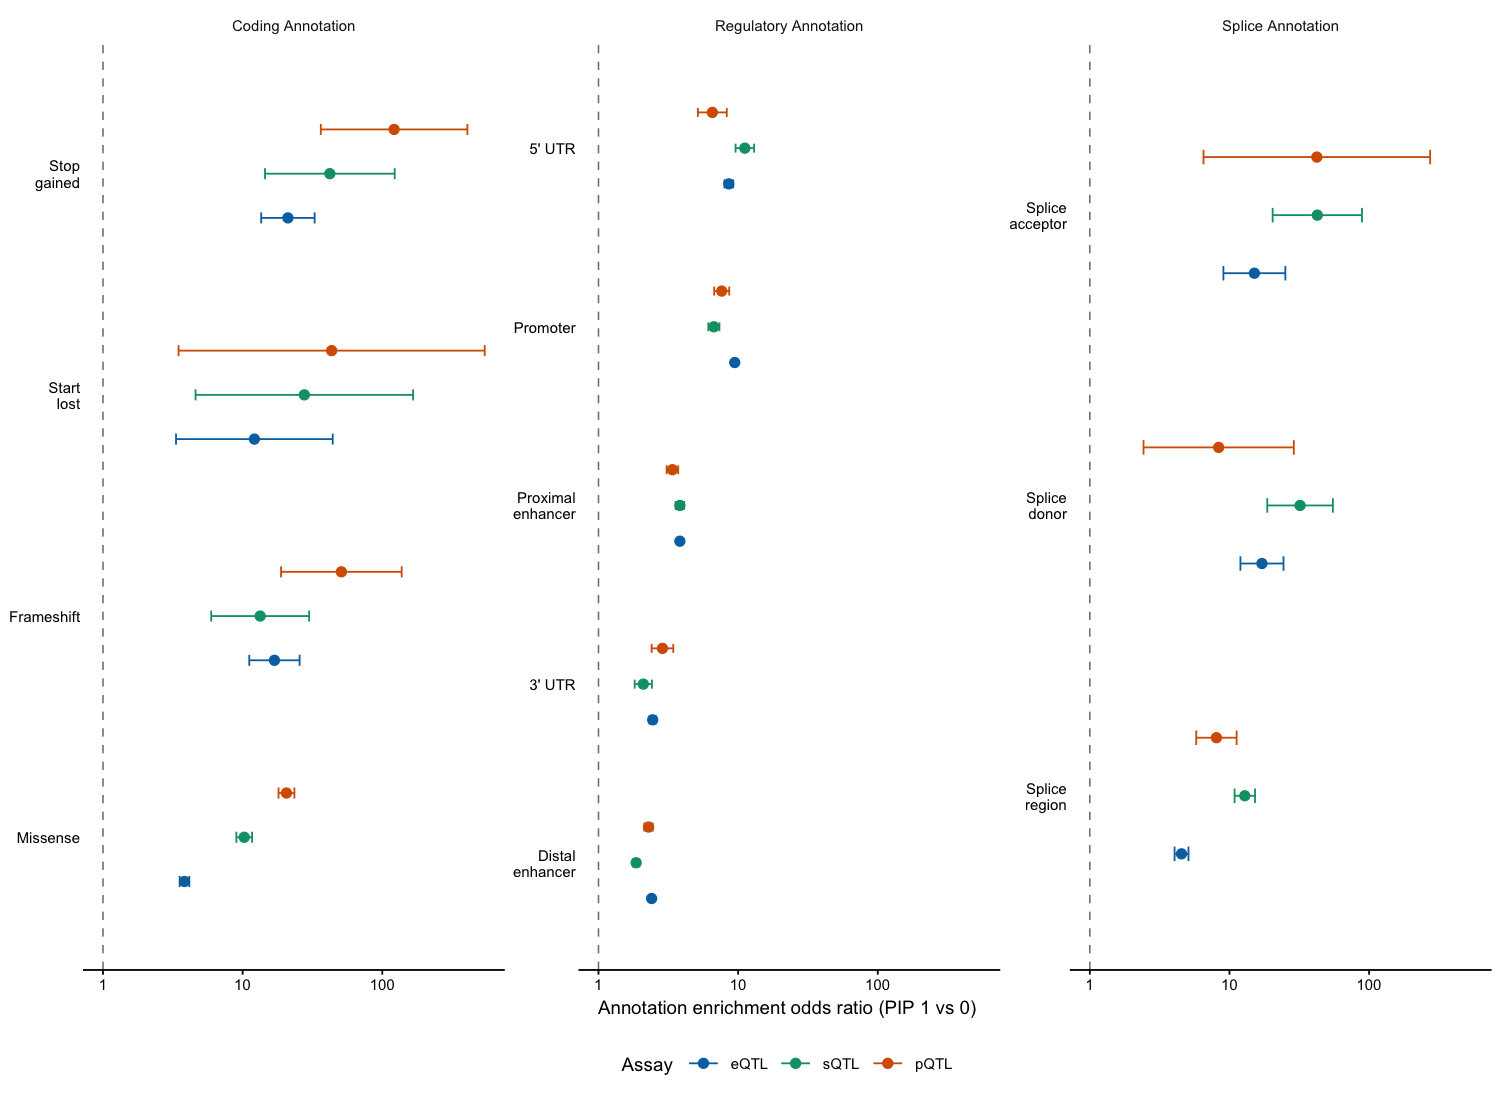

In [3]:
dodge <- position_dodge(width = 0.6)
figure <- ggplot(enrichment, aes(odds_ratio, reorder(annotation_clean, odds_ratio), colour = type, alpha = significant)) +
  geom_vline(xintercept = 1, linetype = "dashed", colour = "grey50", linewidth = 0.35) +
  geom_errorbar(aes(xmin = lower, xmax = upper), orientation = "y", width = 0.15, position = dodge) +
  geom_point(size = 2, position = dodge) +
  facet_wrap(~functional_group, scales = "free_y", nrow = 1) +
  scale_x_log10(labels = scales::label_number()) +
  scale_colour_manual(values = c(eQTL = "#0072B2", sQTL = "#009E73", pQTL = "#D55E00"), name = "Assay") +
  scale_alpha_manual(values = c(`FALSE` = 0.3, `TRUE` = 1),
                     labels = c(`FALSE` = "Adjusted P ≥ 0.05", `TRUE` = "Adjusted P < 0.05"), name = NULL) +
  labs(x = "Annotation enrichment odds ratio (PIP 1 vs 0)", y = NULL) +
  theme_classic(base_size = 9) +
  theme(strip.background = element_blank(), legend.position = "bottom", axis.line.y = element_blank(), axis.ticks.y = element_blank())
if (n_distinct(enrichment$significant) == 1L) figure <- figure + guides(alpha = "none")
print(figure)


## Save aggregate outputs

Export the figure and saved model summaries. Fine-mapping, variant annotation, and logistic-model fitting remain upstream steps.


In [4]:
save_plot(figure, "supplements/S15", 184, 120)
readr::write_tsv(enrichment %>% select(type, functional_group, annotation_clean, estimate,
                                      conf.low, conf.high, odds_ratio, lower, upper, p.value, padj),
                 output_file("supplements/S15_model_summaries.tsv"))


Export aggregate plot: supplements/S15
